# 04. Đánh giá mô hình và tổng hợp Excel

**Đề tài:** Hệ thống khuyến nghị cây trồng

Đánh giá 6 thuật toán từ notebook `03_model_training`, mỗi thuật toán có
cấu hình **mặc định** và **GridSearch** (tổng cộng 12 cấu hình).

- Dùng tập test riêng, không dùng test để chọn tham số hay fit lại mô hình.
- Bảng tổng hợp chỉ giữ **13 tiêu chí**: nhận diện mô hình/cấu hình, kết quả CV,
  Accuracy/Precision-macro/Recall-macro/F1-macro trên test, Train F1-macro,
  chênh lệch F1 train–validation trong CV và thông tin tái lập.
- Chọn cấu hình theo `CV_f1_macro_mean`; dùng `CV_f1_macro_std` để xem độ ổn định.
  Các chỉ số test chỉ dùng đánh giá cuối cùng.
- Phân tích từng lớp, ma trận nhầm lẫn và các mẫu dự đoán sai.
- Xuất **`notebooks/model_evaluation_results.xlsx`** với 7 sheet báo cáo; thông tin thí nghiệm và lưới tham số nằm trong `Tieu_chi`.

Các mô hình đã được chọn tham số bằng CV trên train. Số liệu CV sau tối ưu
có thể lạc quan; tập test tách biệt là kết quả kiểm tra cuối cùng. Việc xem
nhiều kết quả test cũng không thay thế một tập kiểm định mới trong tương lai.

Các mô hình được trình bày theo cùng thứ tự với notebook 03: SoftMax, KNN, Naive Bayes, SVM, Decision Tree, Random Forest.

## Đọc checkpoint và kiểm tra dữ liệu

Chạy notebook 03 trước. Có thể khởi động lại kernel rồi chạy riêng notebook này.
Mã SHA-256 giúp tránh đánh giá nhầm checkpoint với bộ dữ liệu đã thay đổi.

In [1]:
import hashlib
import json
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import openpyxl
import pandas as pd
import seaborn as sns
from IPython.display import display
from openpyxl.formatting.rule import ColorScaleRule
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter
from openpyxl.worksheet.views import Selection
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from threadpoolctl import threadpool_limits

project_dir = Path.cwd().resolve()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent
data_dir = project_dir / "data" / "processed"
notebook_dir = project_dir / "notebooks"
checkpoint_path = notebook_dir / "model_training_results.joblib"
excel_path = notebook_dir / "model_evaluation_results.xlsx"
if not checkpoint_path.is_file():
    raise FileNotFoundError("Chạy notebook 03_model_training.ipynb trước để tạo checkpoint.")
artifact = joblib.load(checkpoint_path)
assert artifact["schema_version"] == 1
for name, expected_hash in artifact["data_hashes"].items():
    actual_hash = hashlib.sha256((data_dir / name).read_bytes()).hexdigest()
    if actual_hash != expected_hash:
        raise ValueError(f"Dữ liệu {name} đã thay đổi; chạy lại notebook 03 trước khi đánh giá.")

X_train = pd.read_csv(data_dir / "X_train.csv")
X_test = pd.read_csv(data_dir / "X_test.csv")
y_train = pd.read_csv(data_dir / "y_train.csv")["label"]
y_test = pd.read_csv(data_dir / "y_test.csv")["label"]
classes = artifact["classes"]
assert X_train.columns.tolist() == X_test.columns.tolist() == artifact["features"]
assert len(X_train) == len(y_train) == artifact["train_samples"]
assert len(X_test) == len(y_test) and len(X_test) > 0
assert np.isfinite(X_test.to_numpy(dtype=float)).all()
assert not y_test.isna().any() and set(y_test).issubset(classes)
train_records = X_train.assign(label=y_train)
test_records = X_test.assign(label=y_test)
overlap = pd.util.hash_pandas_object(train_records, index=False).isin(
    pd.util.hash_pandas_object(test_records, index=False)
).sum()
assert overlap == 0, "Phát hiện mẫu trùng giữa train và test."

plt.rcParams.update({"font.family": "Arial", "axes.unicode_minus": False})
pd.set_option("display.max_columns", 13)
pd.set_option("display.max_colwidth", 100)
class_distribution = pd.DataFrame({
    "Class": classes,
    "Train_samples": y_train.value_counts().reindex(classes).to_numpy(),
    "Test_samples": y_test.value_counts().reindex(classes, fill_value=0).to_numpy(),
})
# Một nguồn định nghĩa cho bảng hiển thị, file Excel và kiểm tra 13 cột.
criteria_guide = pd.DataFrame([
    ("Model", "—", "Nhận diện mô hình"),
    ("Configuration", "—", "Phân biệt Baseline (Mặc định) / Tuned (GridSearch)"),
    ("CV_accuracy_mean", "Càng cao càng tốt", "Chỉ số bổ sung trên validation"),
    ("CV_f1_macro_mean", "Càng cao càng tốt", "Tiêu chí chính để chọn cấu hình"),
    ("CV_f1_macro_std", "Càng thấp càng ổn định", "Độ biến động F1-macro giữa các fold"),
    ("Test_accuracy", "Càng cao càng tốt", "Đánh giá cuối trên tập test"),
    ("Test_precision_macro", "Càng cao càng tốt", "Đánh giá cuối trên tập test"),
    ("Test_recall_macro", "Càng cao càng tốt", "Đánh giá cuối trên tập test"),
    ("Test_f1_macro", "Càng cao càng tốt", "Đánh giá cuối trên tập test"),
    ("Train_f1_macro", "Không có hướng tối ưu riêng", "F1 trên toàn bộ train; đối chiếu CV/test để phân tích overfitting"),
    ("CV_train_validation_gap_F1", "Thường gần 0", "F1 train trung bình trong CV trừ F1 validation trung bình; phân tích overfitting"),
    ("Preprocessing", "—", "Tái lập bước tiền xử lý"),
    ("Best_grid_parameters", "—", "Tái lập tham số GridSearch đã chọn; Baseline ghi {}"),
], columns=["Tiêu chí", "Xu hướng tốt", "Vai trò"])
summary_columns = criteria_guide["Tiêu chí"].tolist()
assert len(summary_columns) == len(set(summary_columns)) == 13

print(f"Run ID: {artifact['run_id']}")
print(f"Train: {len(X_train)} mẫu | Test độc lập: {len(X_test)} mẫu | Số lớp: {len(classes)}")
display(class_distribution)

Run ID: fb7e2bfe101c4ed999bc681c47f317a4
Train: 1760 mẫu | Test độc lập: 440 mẫu | Số lớp: 22


,Class,Train_samples,Test_samples
0,apple,80,20
1,banana,80,20
2,blackgram,80,20
3,chickpea,80,20
4,coconut,80,20
5,coffee,80,20
6,cotton,80,20
7,grapes,80,20
8,jute,80,20
9,kidneybeans,80,20


## Quy trình đánh giá dùng chung

Chỉ predict bằng các pipeline đã fit. Mỗi mục sau đánh giá hai cấu hình và hiển thị báo cáo từng lớp của cấu hình GridSearch. Macro là trung bình không trọng số giữa các lớp. `Train_f1_macro` được tính trên toàn bộ train sau khi fit lại; gap CV dùng điểm train/validation của từng fold.

In [2]:
def calculate_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, labels=classes, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, labels=classes, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, labels=classes, average="macro", zero_division=0),
    }

evaluation_rows, report_rows, matrix_rows, prediction_frames = [], [], [], []
confusion_matrices = {}
def evaluate_model(name):
    configurations = artifact["fitted_models"][name]
    with threadpool_limits(limits=1):
        for variant, estimator in configurations.items():
            train_prediction = estimator.predict(X_train)
            test_prediction = estimator.predict(X_test)
            row = {
                "Model": name, "Configuration": variant,
                "Train_f1_macro": f1_score(y_train, train_prediction, labels=classes, average="macro", zero_division=0),
            }
            row.update({f"Test_{metric}": value for metric, value in calculate_metrics(y_test, test_prediction).items()})
            evaluation_rows.append(row)

            report = classification_report(
                y_test, test_prediction, labels=classes, target_names=classes,
                output_dict=True, zero_division=0,
            )
            for label in classes + ["macro avg"]:
                values = report[label]
                report_rows.append({"Model": name, "Configuration": variant, "Class": label,
                                    "Precision": values["precision"], "Recall": values["recall"],
                                    "F1_score": values["f1-score"], "Support": int(values["support"])})

            matrix = confusion_matrix(y_test, test_prediction, labels=classes)
            confusion_matrices[(name, variant)] = matrix
            for label, values in zip(classes, matrix):
                matrix_rows.append({"Model": name, "Configuration": variant, "Actual_class": label,
                                    **{predicted: int(count) for predicted, count in zip(classes, values)}})

            predictions = X_test.copy()
            predictions.insert(0, "Test_row", np.arange(1, len(X_test) + 1))
            predictions.insert(0, "Configuration", variant)
            predictions.insert(0, "Model", name)
            predictions["Actual_label"] = y_test.to_numpy()
            predictions["Predicted_label"] = test_prediction
            predictions["Correct"] = test_prediction == y_test.to_numpy()
            prediction_frames.append(predictions)

## 1. SoftMax

Đối chiếu kết quả KFold với đánh giá trên tập test riêng của cấu hình mặc định và GridSearch.

In [3]:
evaluate_model("SoftMax")

model_evaluation = pd.DataFrame(evaluation_rows)
model_evaluation = model_evaluation.loc[model_evaluation["Model"] == "SoftMax"]
model_evaluation = artifact["training_summary"].merge(
    model_evaluation, on=["Model", "Configuration"], validate="one_to_one"
)
display(model_evaluation[summary_columns])
model_report = pd.DataFrame(report_rows)
display(model_report.loc[
    (model_report["Model"] == "SoftMax") & (model_report["Configuration"] == "GridSearch")
].set_index("Class")[["Precision", "Recall", "F1_score", "Support"]])

,Model,Configuration,CV_accuracy_mean,CV_f1_macro_mean,CV_f1_macro_std,Test_accuracy,Test_precision_macro,Test_recall_macro,Test_f1_macro,Train_f1_macro,CV_train_validation_gap_F1,Preprocessing,Best_grid_parameters
0,SoftMax,Mặc định,0.968182,0.967824,0.006765,0.972727,0.974022,0.972727,0.972464,0.973841,0.006608,StandardScaler,{}
1,SoftMax,GridSearch,0.977841,0.977581,0.005849,0.984091,0.985197,0.984091,0.984049,0.990316,0.012600,StandardScaler,"{""model__C"": 100.0}"


,Precision,Recall,F1_score,Support
Class,,,,
apple,1.000000,1.000000,1.000000,20
banana,1.000000,1.000000,1.000000,20
blackgram,0.952381,1.000000,0.975610,20
chickpea,1.000000,1.000000,1.000000,20
coconut,1.000000,1.000000,1.000000,20
coffee,1.000000,1.000000,1.000000,20
cotton,0.952381,1.000000,0.975610,20
grapes,1.000000,1.000000,1.000000,20
jute,0.869565,1.000000,0.930233,20


## 2. KNN

Đối chiếu kết quả KFold với đánh giá trên tập test riêng của cấu hình mặc định và GridSearch.

In [4]:
evaluate_model("KNN")

model_evaluation = pd.DataFrame(evaluation_rows)
model_evaluation = model_evaluation.loc[model_evaluation["Model"] == "KNN"]
model_evaluation = artifact["training_summary"].merge(
    model_evaluation, on=["Model", "Configuration"], validate="one_to_one"
)
display(model_evaluation[summary_columns])
model_report = pd.DataFrame(report_rows)
display(model_report.loc[
    (model_report["Model"] == "KNN") & (model_report["Configuration"] == "GridSearch")
].set_index("Class")[["Precision", "Recall", "F1_score", "Support"]])

,Model,Configuration,CV_accuracy_mean,CV_f1_macro_mean,CV_f1_macro_std,Test_accuracy,Test_precision_macro,Test_recall_macro,Test_f1_macro,Train_f1_macro,CV_train_validation_gap_F1,Preprocessing,Best_grid_parameters
0,KNN,Mặc định,0.965341,0.965011,0.012439,0.979545,0.980356,0.979545,0.979283,0.984702,0.017961,StandardScaler,{}
1,KNN,GridSearch,0.975568,0.975440,0.011260,0.981818,0.982348,0.981818,0.981690,1.000000,0.024560,StandardScaler,"{""model__n_neighbors"": 5, ""model__p"": 1, ""model__weights"": ""distance""}"


,Precision,Recall,F1_score,Support
Class,,,,
apple,1.000000,1.000000,1.000000,20
banana,1.000000,1.000000,1.000000,20
blackgram,1.000000,1.000000,1.000000,20
chickpea,1.000000,1.000000,1.000000,20
coconut,0.952381,1.000000,0.975610,20
coffee,1.000000,1.000000,1.000000,20
cotton,0.952381,1.000000,0.975610,20
grapes,1.000000,1.000000,1.000000,20
jute,0.952381,1.000000,0.975610,20


## 3. Naive Bayes

Đối chiếu kết quả KFold với đánh giá trên tập test riêng của cấu hình mặc định và GridSearch.

In [5]:
evaluate_model("Naive Bayes")

model_evaluation = pd.DataFrame(evaluation_rows)
model_evaluation = model_evaluation.loc[model_evaluation["Model"] == "Naive Bayes"]
model_evaluation = artifact["training_summary"].merge(
    model_evaluation, on=["Model", "Configuration"], validate="one_to_one"
)
display(model_evaluation[summary_columns])
model_report = pd.DataFrame(report_rows)
display(model_report.loc[
    (model_report["Model"] == "Naive Bayes") & (model_report["Configuration"] == "GridSearch")
].set_index("Class")[["Precision", "Recall", "F1_score", "Support"]])

,Model,Configuration,CV_accuracy_mean,CV_f1_macro_mean,CV_f1_macro_std,Test_accuracy,Test_precision_macro,Test_recall_macro,Test_f1_macro,Train_f1_macro,CV_train_validation_gap_F1,Preprocessing,Best_grid_parameters
0,Naive Bayes,Mặc định,0.994886,0.994871,0.004192,0.995455,0.995868,0.995455,0.995443,0.994883,-0.000274,Dữ liệu gốc,{}
1,Naive Bayes,GridSearch,0.994886,0.994871,0.004192,0.995455,0.995868,0.995455,0.995443,0.994883,-0.000274,Dữ liệu gốc,"{""model__var_smoothing"": 1e-12}"


,Precision,Recall,F1_score,Support
Class,,,,
apple,1.000000,1.000000,1.000000,20
banana,1.000000,1.000000,1.000000,20
blackgram,1.000000,1.000000,1.000000,20
chickpea,1.000000,1.000000,1.000000,20
coconut,1.000000,1.000000,1.000000,20
coffee,1.000000,1.000000,1.000000,20
cotton,1.000000,1.000000,1.000000,20
grapes,1.000000,1.000000,1.000000,20
jute,0.909091,1.000000,0.952381,20


## 4. SVM

Đối chiếu kết quả KFold với đánh giá trên tập test riêng của cấu hình mặc định và GridSearch.

In [6]:
evaluate_model("SVM")

model_evaluation = pd.DataFrame(evaluation_rows)
model_evaluation = model_evaluation.loc[model_evaluation["Model"] == "SVM"]
model_evaluation = artifact["training_summary"].merge(
    model_evaluation, on=["Model", "Configuration"], validate="one_to_one"
)
display(model_evaluation[summary_columns])
model_report = pd.DataFrame(report_rows)
display(model_report.loc[
    (model_report["Model"] == "SVM") & (model_report["Configuration"] == "GridSearch")
].set_index("Class")[["Precision", "Recall", "F1_score", "Support"]])

,Model,Configuration,CV_accuracy_mean,CV_f1_macro_mean,CV_f1_macro_std,Test_accuracy,Test_precision_macro,Test_recall_macro,Test_f1_macro,Train_f1_macro,CV_train_validation_gap_F1,Preprocessing,Best_grid_parameters
0,SVM,Mặc định,0.978977,0.978803,0.010624,0.984091,0.985610,0.984091,0.984038,0.985792,0.005327,StandardScaler,{}
1,SVM,GridSearch,0.985795,0.985696,0.001775,0.988636,0.989742,0.988636,0.988595,0.990317,0.004910,StandardScaler,"{""model__C"": 10.0, ""model__kernel"": ""linear""}"


,Precision,Recall,F1_score,Support
Class,,,,
apple,1.000000,1.000000,1.000000,20
banana,1.000000,1.000000,1.000000,20
blackgram,1.000000,1.000000,1.000000,20
chickpea,1.000000,1.000000,1.000000,20
coconut,1.000000,1.000000,1.000000,20
coffee,1.000000,1.000000,1.000000,20
cotton,0.952381,1.000000,0.975610,20
grapes,1.000000,1.000000,1.000000,20
jute,0.869565,1.000000,0.930233,20


## 5. Decision Tree

Đối chiếu kết quả KFold với đánh giá trên tập test riêng của cấu hình mặc định và GridSearch.

In [7]:
evaluate_model("Decision Tree")

model_evaluation = pd.DataFrame(evaluation_rows)
model_evaluation = model_evaluation.loc[model_evaluation["Model"] == "Decision Tree"]
model_evaluation = artifact["training_summary"].merge(
    model_evaluation, on=["Model", "Configuration"], validate="one_to_one"
)
display(model_evaluation[summary_columns])
model_report = pd.DataFrame(report_rows)
display(model_report.loc[
    (model_report["Model"] == "Decision Tree") & (model_report["Configuration"] == "GridSearch")
].set_index("Class")[["Precision", "Recall", "F1_score", "Support"]])

,Model,Configuration,CV_accuracy_mean,CV_f1_macro_mean,CV_f1_macro_std,Test_accuracy,Test_precision_macro,Test_recall_macro,Test_f1_macro,Train_f1_macro,CV_train_validation_gap_F1,Preprocessing,Best_grid_parameters
0,Decision Tree,Mặc định,0.985227,0.985209,0.006810,0.979545,0.980598,0.979545,0.979423,1.000000,0.014791,Dữ liệu gốc,{}
1,Decision Tree,GridSearch,0.985795,0.985795,0.005088,0.979545,0.980598,0.979545,0.979423,0.998295,0.010787,Dữ liệu gốc,"{""model__criterion"": ""gini"", ""model__max_depth"": null, ""model__min_samples_leaf"": 2}"


,Precision,Recall,F1_score,Support
Class,,,,
apple,1.000000,1.000000,1.000000,20
banana,1.000000,1.000000,1.000000,20
blackgram,1.000000,0.800000,0.888889,20
chickpea,1.000000,1.000000,1.000000,20
coconut,1.000000,1.000000,1.000000,20
coffee,1.000000,1.000000,1.000000,20
cotton,1.000000,1.000000,1.000000,20
grapes,1.000000,1.000000,1.000000,20
jute,0.950000,0.950000,0.950000,20


## 6. Random Forest

Đối chiếu kết quả KFold với đánh giá trên tập test riêng của cấu hình mặc định và GridSearch.

In [8]:
evaluate_model("Random Forest")

model_evaluation = pd.DataFrame(evaluation_rows)
model_evaluation = model_evaluation.loc[model_evaluation["Model"] == "Random Forest"]
model_evaluation = artifact["training_summary"].merge(
    model_evaluation, on=["Model", "Configuration"], validate="one_to_one"
)
display(model_evaluation[summary_columns])
model_report = pd.DataFrame(report_rows)
display(model_report.loc[
    (model_report["Model"] == "Random Forest") & (model_report["Configuration"] == "GridSearch")
].set_index("Class")[["Precision", "Recall", "F1_score", "Support"]])

,Model,Configuration,CV_accuracy_mean,CV_f1_macro_mean,CV_f1_macro_std,Test_accuracy,Test_precision_macro,Test_recall_macro,Test_f1_macro,Train_f1_macro,CV_train_validation_gap_F1,Preprocessing,Best_grid_parameters
0,Random Forest,Mặc định,0.993750,0.993703,0.006140,0.995455,0.995671,0.995455,0.995452,1.0,0.006297,Dữ liệu gốc,{}
1,Random Forest,GridSearch,0.994318,0.994292,0.004782,0.995455,0.995671,0.995455,0.995452,1.0,0.005708,Dữ liệu gốc,"{""model__max_depth"": null, ""model__max_features"": ""sqrt"", ""model__min_samples_leaf"": 1, ""model__..."


,Precision,Recall,F1_score,Support
Class,,,,
apple,1.000000,1.000000,1.000000,20
banana,1.000000,1.000000,1.000000,20
blackgram,1.000000,0.950000,0.974359,20
chickpea,1.000000,1.000000,1.000000,20
coconut,1.000000,1.000000,1.000000,20
coffee,1.000000,1.000000,1.000000,20
cotton,1.000000,1.000000,1.000000,20
grapes,1.000000,1.000000,1.000000,20
jute,0.952381,1.000000,0.975610,20


## 7. Tổng hợp đánh giá

Bảng chỉ có 13 tiêu chí, theo thứ tự mô hình 1–6 và hai cấu hình Mặc định/GridSearch.
Điểm Accuracy/Precision/Recall/F1 càng cao càng tốt; `CV_f1_macro_std` thấp cho biết
F1 ít biến động giữa các fold. Gap CV gần 0 chỉ hữu ích khi đi cùng điểm validation tốt;
gap nhỏ vẫn có thể xuất hiện khi cả train và validation đều thấp. Gap âm nhẹ có thể do
dao động giữa các fold. `Train_f1_macro` là điểm trên toàn bộ train, không phải điểm
train trung bình dùng để tính gap CV.

In [9]:
evaluation_results = pd.DataFrame(evaluation_rows)
full_summary = artifact["training_summary"].merge(
    evaluation_results, on=["Model", "Configuration"], how="inner", validate="one_to_one"
)
assert len(full_summary) == 12
classification_results = pd.DataFrame(report_rows)
confusion_results = pd.DataFrame(matrix_rows)
test_predictions = pd.concat(prediction_frames, ignore_index=True)
misclassified = test_predictions.loc[~test_predictions["Correct"]].copy()

tuned_order = artifact["model_order"]
row_order = [(name, variant) for name in tuned_order for variant in ("Mặc định", "GridSearch")]
full_summary = full_summary.set_index(["Model", "Configuration"]).loc[row_order].reset_index()
summary = full_summary[summary_columns].copy()
assert not summary.isna().any().any()

display(summary.round(5))
print("Cách đọc 13 tiêu chí:")
display(criteria_guide)

Cách đọc 13 tiêu chí:


,Model,Configuration,CV_accuracy_mean,CV_f1_macro_mean,CV_f1_macro_std,Test_accuracy,Test_precision_macro,Test_recall_macro,Test_f1_macro,Train_f1_macro,CV_train_validation_gap_F1,Preprocessing,Best_grid_parameters
0,SoftMax,Mặc định,0.96818,0.96782,0.00677,0.97273,0.97402,0.97273,0.97246,0.97384,0.00661,StandardScaler,{}
1,SoftMax,GridSearch,0.97784,0.97758,0.00585,0.98409,0.98520,0.98409,0.98405,0.99032,0.01260,StandardScaler,"{""model__C"": 100.0}"
2,KNN,Mặc định,0.96534,0.96501,0.01244,0.97955,0.98036,0.97955,0.97928,0.98470,0.01796,StandardScaler,{}
3,KNN,GridSearch,0.97557,0.97544,0.01126,0.98182,0.98235,0.98182,0.98169,1.00000,0.02456,StandardScaler,"{""model__n_neighbors"": 5, ""model__p"": 1, ""model__weights"": ""distance""}"
4,Naive Bayes,Mặc định,0.99489,0.99487,0.00419,0.99545,0.99587,0.99545,0.99544,0.99488,-0.00027,Dữ liệu gốc,{}
5,Naive Bayes,GridSearch,0.99489,0.99487,0.00419,0.99545,0.99587,0.99545,0.99544,0.99488,-0.00027,Dữ liệu gốc,"{""model__var_smoothing"": 1e-12}"
6,SVM,Mặc định,0.97898,0.97880,0.01062,0.98409,0.98561,0.98409,0.98404,0.98579,0.00533,StandardScaler,{}
7,SVM,GridSearch,0.98580,0.98570,0.00177,0.98864,0.98974,0.98864,0.98859,0.99032,0.00491,StandardScaler,"{""model__C"": 10.0, ""model__kernel"": ""linear""}"
8,Decision Tree,Mặc định,0.98523,0.98521,0.00681,0.97955,0.98060,0.97955,0.97942,1.00000,0.01479,Dữ liệu gốc,{}
9,Decision Tree,GridSearch,0.98580,0.98580,0.00509,0.97955,0.98060,0.97955,0.97942,0.99830,0.01079,Dữ liệu gốc,"{""model__criterion"": ""gini"", ""model__max_depth"": null, ""model__min_samples_leaf"": 2}"


,Tiêu chí,Xu hướng tốt,Vai trò
0,Model,—,Nhận diện mô hình
1,Configuration,—,Phân biệt Baseline (Mặc định) / Tuned (GridSearch)
2,CV_accuracy_mean,Càng cao càng tốt,Chỉ số bổ sung trên validation
3,CV_f1_macro_mean,Càng cao càng tốt,Tiêu chí chính để chọn cấu hình
4,CV_f1_macro_std,Càng thấp càng ổn định,Độ biến động F1-macro giữa các fold
5,Test_accuracy,Càng cao càng tốt,Đánh giá cuối trên tập test
6,Test_precision_macro,Càng cao càng tốt,Đánh giá cuối trên tập test
7,Test_recall_macro,Càng cao càng tốt,Đánh giá cuối trên tập test
8,Test_f1_macro,Càng cao càng tốt,Đánh giá cuối trên tập test
9,Train_f1_macro,Không có hướng tối ưu riêng,F1 trên toàn bộ train; đối chiếu CV/test để phân tích overfitting


## 8. So sánh trước và sau tối ưu

Đặt cấu hình Mặc định và GridSearch cạnh nhau theo từng mô hình, sử dụng các
tiêu chí đã giữ lại. Tối ưu theo F1-macro CV không bảo đảm điểm test cao hơn.

,Model,Configuration,CV_accuracy_mean,CV_f1_macro_mean,CV_f1_macro_std,Test_accuracy,Test_f1_macro,Best_grid_parameters
0,SoftMax,Mặc định,0.96818,0.96782,0.00677,0.97273,0.97246,{}
1,SoftMax,GridSearch,0.97784,0.97758,0.00585,0.98409,0.98405,"{""model__C"": 100.0}"
2,KNN,Mặc định,0.96534,0.96501,0.01244,0.97955,0.97928,{}
3,KNN,GridSearch,0.97557,0.97544,0.01126,0.98182,0.98169,"{""model__n_neighbors"": 5, ""model__p"": 1, ""model__weights"": ""distance""}"
4,Naive Bayes,Mặc định,0.99489,0.99487,0.00419,0.99545,0.99544,{}
5,Naive Bayes,GridSearch,0.99489,0.99487,0.00419,0.99545,0.99544,"{""model__var_smoothing"": 1e-12}"
6,SVM,Mặc định,0.97898,0.97880,0.01062,0.98409,0.98404,{}
7,SVM,GridSearch,0.98580,0.98570,0.00177,0.98864,0.98859,"{""model__C"": 10.0, ""model__kernel"": ""linear""}"
8,Decision Tree,Mặc định,0.98523,0.98521,0.00681,0.97955,0.97942,{}
9,Decision Tree,GridSearch,0.98580,0.98580,0.00509,0.97955,0.97942,"{""model__criterion"": ""gini"", ""model__max_depth"": null, ""model__min_samples_leaf"": 2}"


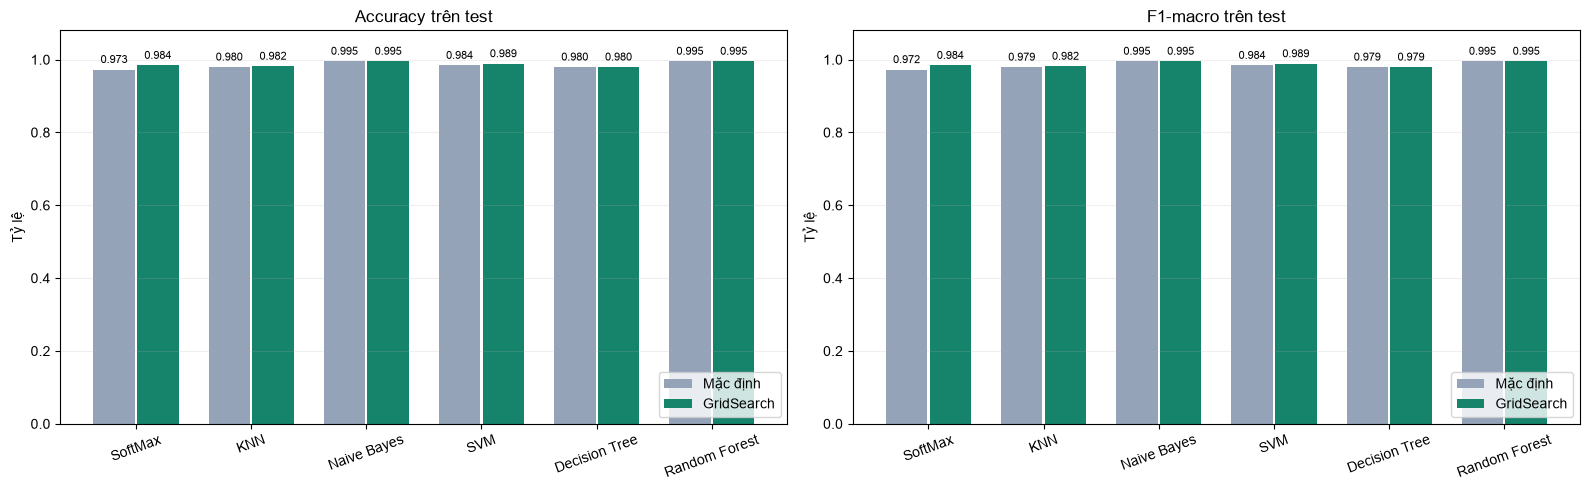

In [10]:
comparison_columns = [
    "Model", "Configuration", "CV_accuracy_mean", "CV_f1_macro_mean", "CV_f1_macro_std",
    "Test_accuracy", "Test_f1_macro", "Best_grid_parameters",
]
optimization_comparison = summary[comparison_columns].copy()
display(optimization_comparison.round(5))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
positions = np.arange(len(tuned_order))
for ax, metric, title in [(axes[0], "Test_accuracy", "Accuracy trên test"),
                          (axes[1], "Test_f1_macro", "F1-macro trên test")]:
    for offset, variant, color in [(-0.19, "Mặc định", "#94a3b8"), (0.19, "GridSearch", "#16836b")]:
        values = full_summary[full_summary["Configuration"] == variant].set_index("Model").loc[tuned_order, metric]
        bars = ax.bar(positions + offset, values, width=0.36, label=variant, color=color)
        ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)
    ax.set(xticks=positions, xticklabels=tuned_order, ylim=(0, 1.08), title=title, ylabel="Tỷ lệ")
    ax.tick_params(axis="x", rotation=20)
    ax.legend(loc="lower right")
    ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

## 9. Đánh giá chi tiết từng lớp và ma trận nhầm lẫn

Hàng là nhãn thực tế, cột là nhãn dự đoán. Biểu đồ thể hiện 6 cấu hình
GridSearch; Excel có ma trận và báo cáo từng lớp của **cả 12 cấu hình**.

Một số dự đoán sai (danh sách đầy đủ trong Excel):


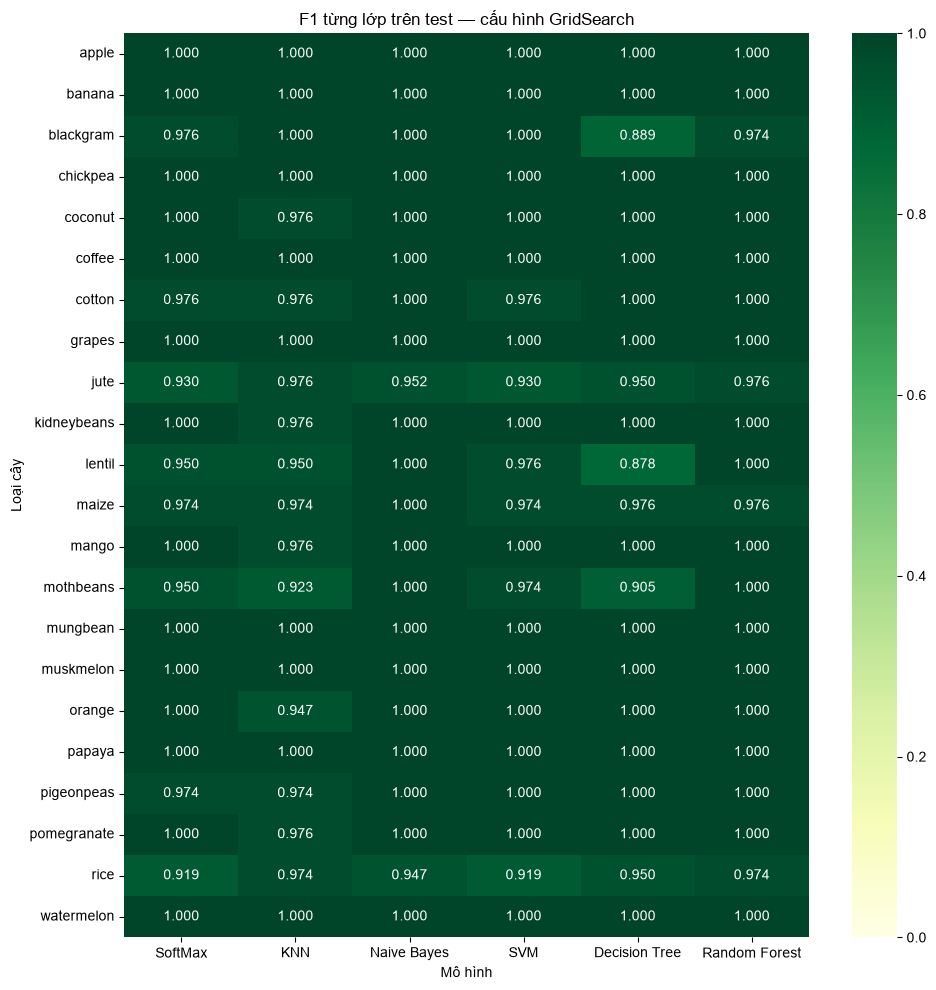

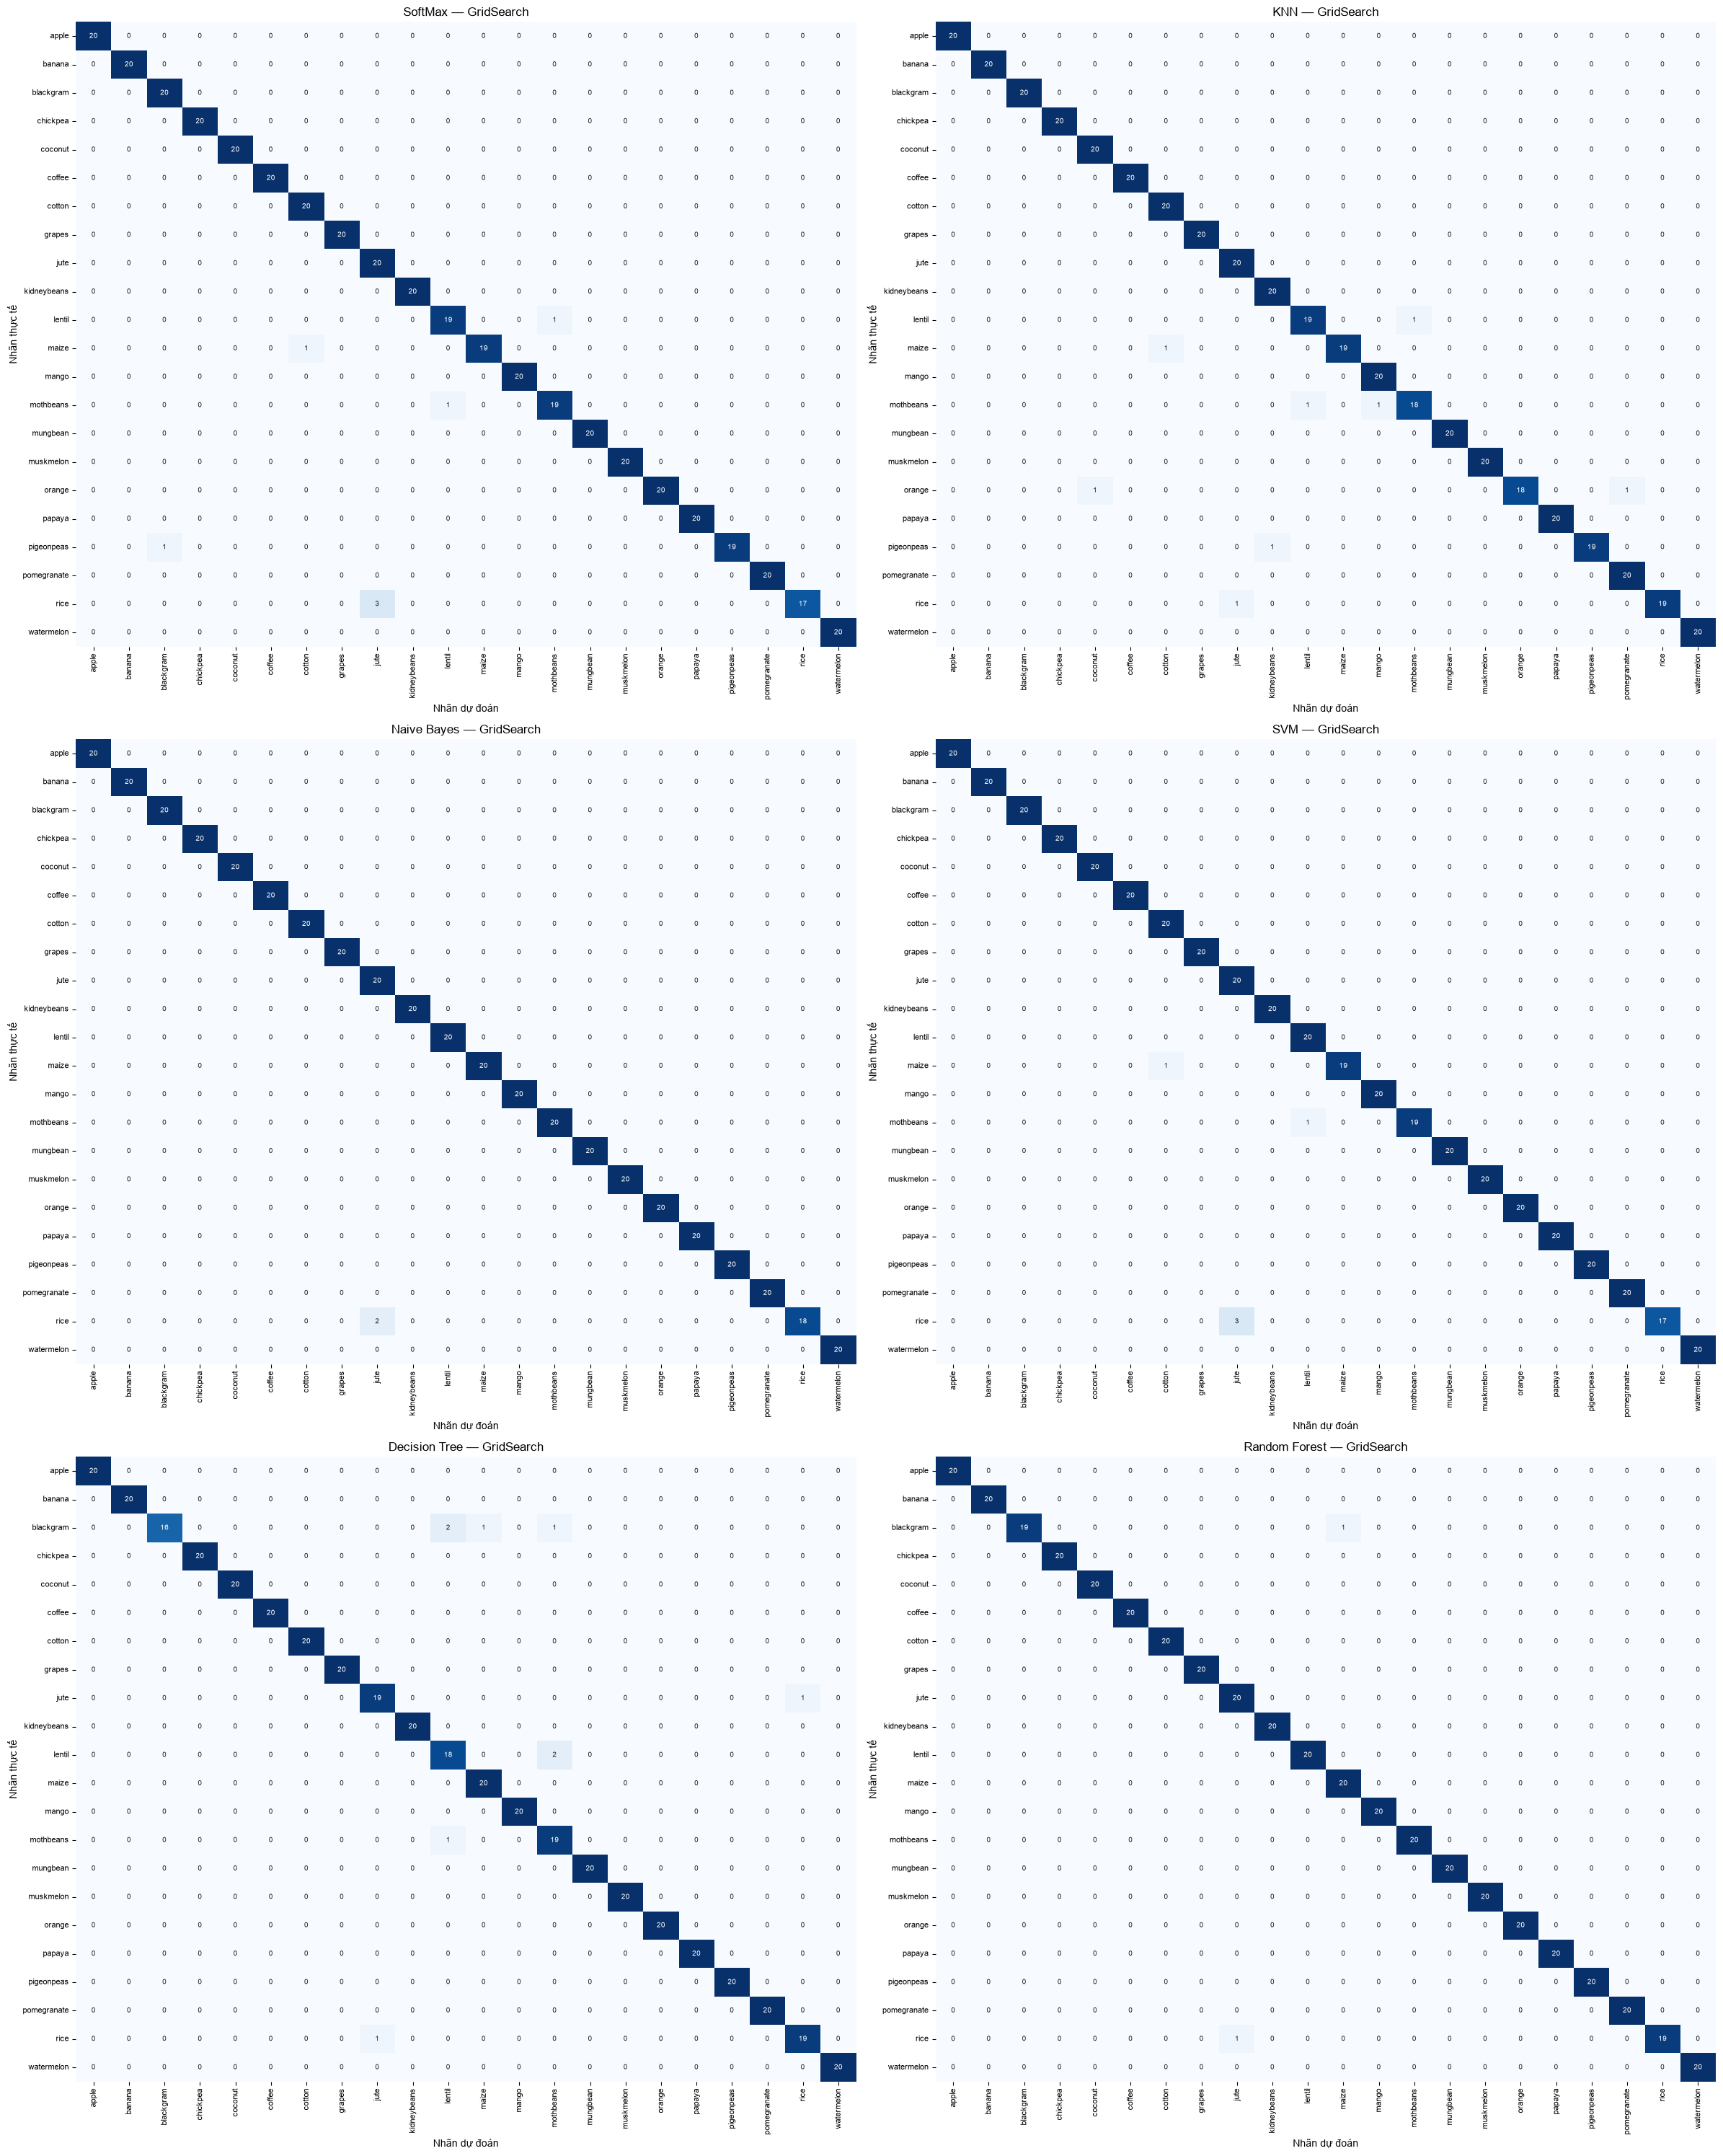

,Model,Configuration,Test_row,N,P,K,temperature,humidity,ph,rainfall,Actual_label,Predicted_label,Correct
26,SoftMax,Mặc định,27,32,43,22,31.999286,54.107746,5.270749,71.626670,mothbeans,mango,False
60,SoftMax,Mặc định,61,27,80,24,28.420628,61.773363,7.815211,49.023668,lentil,blackgram,False
186,SoftMax,Mặc định,187,33,12,15,30.255780,92.032728,6.052318,116.717313,orange,coconut,False
207,SoftMax,Mặc định,208,31,58,15,28.318869,60.194614,6.167855,45.365213,lentil,mothbeans,False
231,SoftMax,Mặc định,232,83,60,36,25.597049,80.145093,6.903986,200.834898,rice,jute,False
344,SoftMax,Mặc định,345,81,41,38,22.678461,83.728744,7.524080,200.913316,rice,jute,False
369,SoftMax,Mặc định,370,78,43,42,21.323763,83.003205,7.283737,192.319754,rice,jute,False
378,SoftMax,Mặc định,379,67,43,39,26.043720,84.969072,5.999969,186.753677,rice,jute,False
385,SoftMax,Mặc định,386,98,44,21,25.771751,74.089114,6.524478,107.493192,maize,cotton,False
396,SoftMax,Mặc định,397,23,58,19,24.170932,58.252046,5.243635,59.189534,mothbeans,lentil,False


In [11]:
tuned_reports = classification_results[
    (classification_results["Configuration"] == "GridSearch") & classification_results["Class"].isin(classes)
]
class_f1 = tuned_reports.pivot(index="Class", columns="Model", values="F1_score").reindex(index=classes, columns=tuned_order)
fig, ax = plt.subplots(figsize=(10, 10))
sns.heatmap(class_f1, annot=True, fmt=".3f", cmap="YlGn", vmin=0, vmax=1, ax=ax)
ax.set(title="F1 từng lớp trên test — cấu hình GridSearch", xlabel="Mô hình", ylabel="Loại cây")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 2, figsize=(24, 30))
for ax, name in zip(axes.flat, tuned_order):
    sns.heatmap(confusion_matrices[(name, "GridSearch")], annot=True, fmt="d", cmap="Blues",
                xticklabels=classes, yticklabels=classes, cbar=False, ax=ax,
                annot_kws={"fontsize": 7})
    ax.set(title=f"{name} — GridSearch", xlabel="Nhãn dự đoán", ylabel="Nhãn thực tế")
    ax.tick_params(axis="x", labelrotation=90, labelsize=8)
    ax.tick_params(axis="y", labelrotation=0, labelsize=8)
fig.tight_layout()
plt.show()

print("Một số dự đoán sai (danh sách đầy đủ trong Excel):")
display(misclassified.head(20))

## 10. Xuất Excel tổng hợp

Báo cáo gồm **7 sheet**, theo thứ tự:
`Tong_hop`, `Tieu_chi`, `So_sanh_toi_uu`, `CV_tung_fold`,
`Bao_cao_theo_lop`, `Confusion Matrix`, `Sai_phan_loai`.

`Tieu_chi` là hướng dẫn chung, gồm ba phần: giải thích 13 tiêu chí,
mô tả cấu hình thí nghiệm và lưới siêu tham số đã thử. Kết quả tốt nhất
của GridSearch được ghi trong `Best_grid_parameters` ở bảng tổng hợp.
Danh sách mọi ứng viên GridSearch và toàn bộ dự đoán test chỉ phục vụ
tính toán; phân bố nhãn có thể xem trong phần khám phá dữ liệu.

Các chỉ số hiển thị dạng phần trăm nhưng giữ giá trị gốc để tiếp tục tính toán.
Nếu file đích đang được mở và không thể ghi đè, notebook lưu bản rút gọn
vào `model_evaluation_results_compact.xlsx` trong cùng thư mục.

In [12]:
evaluated_at = datetime.now().astimezone().isoformat(timespec="seconds")
info_rows = [
    ("Đề tài", "Hệ thống khuyến nghị cây trồng"),
    ("Run_ID", artifact["run_id"]),
    ("Bắt đầu huấn luyện", artifact["started_at"]),
    ("Kết thúc huấn luyện", artifact["finished_at"]),
    ("Thời điểm đánh giá", evaluated_at),
    ("Số mẫu train", len(X_train)), ("Số mẫu test", len(X_test)),
    ("Số đặc trưng", len(artifact["features"])), ("Số lớp", len(classes)),
    ("Đặc trưng", ", ".join(artifact["features"])),
    ("Các thuật toán", ", ".join(artifact["fitted_models"])),
    ("Số cấu hình đánh giá", len(summary)),
    ("Cross-validation", artifact["cv_method"]),
    ("Số fold", artifact["n_splits"]), ("Random state", artifact["random_state"]),
    ("Số luồng", artifact["n_jobs"]),
    ("Chọn tham số", "GridSearchCV; refit=f1_macro; chỉ sử dụng train; cùng fold cho mọi cấu hình."),
    ("Thứ tự mô hình", "1. SoftMax; 2. KNN; 3. Naive Bayes; 4. SVM; 5. Decision Tree; 6. Random Forest."),
    ("Lựa chọn chính", "Theo CV_f1_macro_mean; CV_f1_macro_std mô tả độ ổn định. Test chỉ dùng đánh giá cuối."),
    ("Mặc định", "Siêu tham số mặc định; SoftMax max_iter=5000; random_state=42 cho thuật toán có ngẫu nhiên."),
    ("SoftMax", "LogisticRegression, solver=lbfgs, multinomial/SoftMax cho 22 lớp."),
    ("Naive Bayes", "GaussianNB cho đặc trưng số liên tục."),
    ("Chuẩn hóa", "StandardScaler trong Pipeline của SoftMax, KNN, SVM; fit riêng từng fold. Các mô hình khác dùng dữ liệu gốc."),
    ("Độc lập train/test", f"Số bản ghi trùng giữa train và test: {overlap}. Test không dùng để fit hoặc tìm tham số."),
    ("CV_mean / CV_std", "Trung bình / độ lệch chuẩn trên 5 validation fold; std dùng ddof=0, không phải khoảng tin cậy."),
    ("Giới hạn CV", "Điểm CV của cấu hình GridSearch được chọn dùng cho tối ưu, có thể lạc quan; không phải nested CV."),
    ("Giới hạn test", "Test là đánh giá holdout sau tối ưu. So sánh nhiều mô hình trên test không thay thế kiểm định mới khi tiếp tục phát triển."),
    ("Đơn vị chỉ số", "Giá trị lưu 0–1, hiển thị %. Chênh lệch gap hiển thị theo điểm phần trăm."),
    ("Macro", "Trung bình không trọng số qua các lớp; mỗi lớp có vai trò như nhau."),
    ("Zero division", "Precision/recall/F1 không xác định do mẫu số bằng 0 được quy ước bằng 0, cả CV và test."),
    ("Support", "Số mẫu test của lớp; macro avg có support bằng tổng số mẫu test."),
    ("CV_train_validation_gap_F1", "F1-macro train trung bình trong CV trừ F1-macro validation trung bình."),
    ("Test_row", "Số thứ tự dòng dữ liệu trong X_test.csv, bắt đầu từ 1, không tính header."),
    ("Ma trận nhầm lẫn", "Hàng Actual_class là nhãn thực tế; các cột tên cây là nhãn dự đoán; ô là số mẫu."),
    ("Cấu hình tốt nhất", "Best_grid_parameters trong Tong_hop ghi tham số được chọn để refit; khi đồng hạng lấy ứng viên đầu tiên theo GridSearchCV."),
    ("Cách đọc lưới tham số", "Các tham số trong cùng Nhóm lưới được lấy tích Descartes; các nhóm của cùng mô hình được ghép lại, không nhân chéo."),
    ("Tổng thời gian huấn luyện (giây)", artifact["training_seconds"]),
    ("Tong_hop", "12 cấu hình, đúng 13 tiêu chí theo danh sách trong sheet Tieu_chi."),
    ("So_sanh_toi_uu", "6 thuật toán, mỗi thuật toán 2 dòng Mặc định/GridSearch; chỉ dùng các tiêu chí đã giữ."),
    ("CV_tung_fold", "Train và validation của từng fold cho 12 cấu hình; cấu hình GridSearch dùng tham số đã được chọn."),
    ("Bao_cao_theo_lop", "Precision, recall, F1, support từng lớp và trung bình macro."),
    ("Sai_phan_loai", "Chỉ các dòng test bị phân loại sai, kèm mô hình, cấu hình, nhãn thực tế và nhãn dự đoán."),
    ("Tieu_chi", "Hướng dẫn 13 tiêu chí, mô tả cấu hình thí nghiệm và lưới siêu tham số đã thử."),
]
info_rows.extend((f"Phiên bản {key}", value) for key, value in artifact["versions"].items())
info_rows.append(("Phiên bản openpyxl", openpyxl.__version__))
info_rows.extend((f"SHA256 {name}", digest) for name, digest in artifact["data_hashes"].items())
run_info = pd.DataFrame(info_rows, columns=["Muc", "Noi_dung"])

# Gộp các giá trị tìm kiếm thành một dòng cho mỗi mô hình/nhóm lưới,
# thay vì xuất riêng danh sách 101 ứng viên GridSearch.
search_configuration_rows = []
for (name, group), definition in artifact["grid_definition"].groupby(["Model", "Grid_group"], sort=False):
    parameters = {row.Parameter: json.loads(row.Values) for row in definition.itertuples(index=False)}
    search_configuration_rows.append({
        "Mô hình": name, "Nhóm lưới": int(group),
        "Cấu hình tìm kiếm": json.dumps(parameters, ensure_ascii=False),
    })
search_configuration = pd.DataFrame(search_configuration_rows)
sheets = {
    "Tong_hop": summary,
    "Tieu_chi": criteria_guide,
    "So_sanh_toi_uu": optimization_comparison,
    "CV_tung_fold": artifact["fold_results"],
    "Bao_cao_theo_lop": classification_results,
    "Confusion Matrix": confusion_results,
    "Sai_phan_loai": misclassified,
}

# Viết qua file tạm để không làm hỏng báo cáo cũ nếu quá trình ghi bị gián đoạn.
temporary_excel_path = excel_path.with_name(excel_path.stem + ".tmp.xlsx")
with pd.ExcelWriter(temporary_excel_path, engine="openpyxl") as writer:
    for sheet_name, frame in sheets.items():
        frame.to_excel(writer, sheet_name=sheet_name, index=False)
        ws = writer.sheets[sheet_name]
        # Set Freeze Panes once: changing C2 to A2 retains stale selections in openpyxl.
        ws.freeze_panes = "A2" if sheet_name == "Tieu_chi" else (
            "D2" if sheet_name in {"Tong_hop", "CV_tung_fold", "Bao_cao_theo_lop", "Confusion Matrix"} else "C2"
        )
        ws.auto_filter.ref = ws.dimensions
        ws.sheet_view.showGridLines = False
        ws.row_dimensions[1].height = 42
        for cell in ws[1]:
            cell.fill = PatternFill("solid", fgColor="174B46")
            cell.font = Font(name="Calibri", color="FFFFFF", bold=True, size=11)
            cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

        for column_index, column in enumerate(frame.columns, 1):
            letter = get_column_letter(column_index)
            sample = frame[column].head(200).fillna("").astype(str)
            max_length = max([len(str(column))] + sample.str.len().tolist())
            width = min(30, max(14, max_length + 2))
            if column in {"Parameters", "Best_grid_parameters", "Values"}:
                width = 58
            if column == "Noi_dung":
                width = 112
            if column in {"Muc", "Tiêu chí"}:
                width = 38
            if column == "Xu hướng tốt":
                width = 38
            if column == "Vai trò":
                width = 90
            if sheet_name == "Confusion Matrix" and column in classes:
                width = 14
            ws.column_dimensions[letter].width = width

            is_metric = (
                str(column).startswith(("CV_accuracy", "CV_f1", "Test_accuracy", "Test_precision",
                                        "Test_recall", "Test_f1", "Train_f1", "Validation_"))
                or column in {"Precision", "Recall", "F1_score", "CV_train_validation_gap_F1"}
            )
            is_delta = "gap" in str(column)
            for row_number in range(2, ws.max_row + 1):
                cell = ws.cell(row_number, column_index)
                cell.font = Font(name="Calibri", size=11)
                cell.alignment = Alignment(vertical="center", wrap_text=column in {
                    "Parameters", "Best_grid_parameters", "Values", "Noi_dung", "Muc", "Tiêu chí", "Xu hướng tốt", "Vai trò"
                })
                if row_number % 2 == 0:
                    cell.fill = PatternFill("solid", fgColor="F0F6F4")
                if is_metric and isinstance(cell.value, (float, int)):
                    cell.number_format = '+0.00%;-0.00%;0.00%' if is_delta else '0.00%'
                elif isinstance(cell.value, float):
                    cell.number_format = '0.0000' if "ms" in str(column) else '0.000'
                if sheet_name in {"Tong_hop", "So_sanh_toi_uu", "Tieu_chi"}:
                    ws.row_dimensions[row_number].height = 66

            if column in {"CV_f1_macro_mean", "Test_f1_macro", "F1_score"} and ws.max_row > 1:
                ws.conditional_formatting.add(
                    f"{letter}2:{letter}{ws.max_row}",
                    ColorScaleRule(start_type="min", start_color="FDE4DB", mid_type="percentile",
                                   mid_value=50, mid_color="FFF8D6", end_type="max", end_color="B7DDCD"),
                )
        if sheet_name == "Confusion Matrix":
            last_column = get_column_letter(ws.max_column)
            ws.conditional_formatting.add(
                f"D2:{last_column}{ws.max_row}",
                ColorScaleRule(start_type="num", start_value=0, start_color="FFFFFF",
                               end_type="num", end_value=int(class_distribution["Test_samples"].max()), end_color="5AAE9B"),
            )
            diagonal_border = Border(bottom=Side(style="thin", color="174B46"))
            for row_number in range(2, ws.max_row + 1):
                actual_class = ws.cell(row_number, 3).value
                diagonal = ws.cell(row_number, 4 + classes.index(actual_class))
                diagonal.font = Font(name="Calibri", bold=True, color="174B46")
                diagonal.border = diagonal_border

    # Nối mô tả thí nghiệm và lưới tham số ngay dưới bảng 13 tiêu chí.
    guide_sheet = writer.sheets["Tieu_chi"]
    guide_sheet.sheet_view.selection = [Selection(pane="bottomLeft", activeCell="A2", sqref="A2")]
    guide_sheet.auto_filter.ref = f"A1:C{len(criteria_guide) + 1}"
    guidance_sections_layout = []
    section_row = len(criteria_guide) + 4
    for title, frame in [
        ("CẤU HÌNH THÍ NGHIỆM", run_info),
        ("LƯỚI SIÊU THAM SỐ ĐÃ THỬ", search_configuration),
    ]:
        guide_sheet.merge_cells(start_row=section_row, start_column=1, end_row=section_row, end_column=3)
        title_cell = guide_sheet.cell(section_row, 1, title)
        title_cell.font = Font(name="Calibri", color="FFFFFF", bold=True, size=12)
        title_cell.fill = PatternFill("solid", fgColor="174B46")
        title_cell.alignment = Alignment(vertical="center")
        guide_sheet.row_dimensions[section_row].height = 30
        frame.to_excel(writer, sheet_name="Tieu_chi", index=False, startrow=section_row)
        header_row = section_row + 1
        guidance_sections_layout.append((title, frame, header_row))
        for row_number in range(header_row, header_row + len(frame) + 1):
            if len(frame.columns) == 2:
                guide_sheet.merge_cells(start_row=row_number, start_column=2, end_row=row_number, end_column=3)
            for column_number in range(1, len(frame.columns) + 1):
                cell = guide_sheet.cell(row_number, column_number)
                is_header = row_number == header_row
                cell.font = Font(name="Calibri", size=11, bold=is_header, color="174B46" if is_header else "000000")
                cell.alignment = Alignment(vertical="center", wrap_text=True)
                cell.fill = PatternFill("solid", fgColor="DDEBE6" if is_header else ("F0F6F4" if row_number % 2 == 0 else "FFFFFF"))
                if isinstance(cell.value, float):
                    cell.number_format = '0.000'
            guide_sheet.row_dimensions[row_number].height = 30 if row_number == header_row else (66 if len(frame.columns) == 3 else 42)
        section_row = header_row + len(frame) + 3

    writer.book.active = 0
    writer.book.properties.title = "Đánh giá 6 mô hình khuyến nghị cây trồng"
    writer.book.properties.subject = "KFold, GridSearchCV và đánh giá holdout"
    writer.book.properties.description = f"Run ID: {artifact['run_id']}; chi tiết phương pháp và lưới tham số trong sheet Tieu_chi."

try:
    temporary_excel_path.replace(excel_path)
except PermissionError:
    # Excel có thể khóa file đang mở; vẫn tạo được báo cáo rút gọn để xem.
    compact_excel_path = excel_path.with_name(excel_path.stem + "_compact.xlsx")
    temporary_excel_path.replace(compact_excel_path)
    excel_path = compact_excel_path
    print("File đích đang bị khóa; đã lưu báo cáo rút gọn thành file riêng.")
print("ĐÃ XUẤT EXCEL:", excel_path)
print(f"{len(sheets)} sheet | {len(summary)} cấu hình | {len(summary_columns)} tiêu chí tổng hợp")

ĐÃ XUẤT EXCEL: D:\HK1_Nam3\MachineLearning\Crop_Recommendation_System\notebooks\model_evaluation_results.xlsx
7 sheet | 12 cấu hình | 13 tiêu chí tổng hợp


## 11. Kiểm tra báo cáo và nhận xét từ kết quả thực tế

Đối chiếu đúng 7 sheet, 13 tiêu chí tổng hợp, từng fold, báo cáo theo lớp,
ma trận nhầm lẫn và các mẫu sai. Kiểm tra thông tin thí nghiệm và lưới tham số
đã được gộp đầy đủ vào `Tieu_chi`. Nhận xét được tính trực tiếp từ kết quả chạy.

In [13]:
with pd.ExcelFile(excel_path, engine="openpyxl") as report_file:
    expected_sheets = [
        "Tong_hop", "Tieu_chi", "So_sanh_toi_uu", "CV_tung_fold",
        "Bao_cao_theo_lop", "Confusion Matrix", "Sai_phan_loai",
    ]
    assert report_file.sheet_names == expected_sheets == list(sheets)
    for sheet_name, expected in sheets.items():
        saved = pd.read_excel(report_file, sheet_name=sheet_name,
                              nrows=len(criteria_guide) if sheet_name == "Tieu_chi" else None)
        pd.testing.assert_frame_equal(saved, expected.reset_index(drop=True), check_dtype=False, atol=1e-12)
    for title, frame, header_row in guidance_sections_layout:
        saved_section = pd.read_excel(report_file, sheet_name="Tieu_chi", header=header_row - 1,
                                      nrows=len(frame), usecols=list(range(len(frame.columns))))
        pd.testing.assert_frame_equal(saved_section, frame, check_dtype=False, atol=1e-12)
    saved_summary = pd.read_excel(report_file, sheet_name="Tong_hop")
    saved_criteria = pd.read_excel(report_file, sheet_name="Tieu_chi", nrows=len(criteria_guide))
    saved_folds = pd.read_excel(report_file, sheet_name="CV_tung_fold")
    saved_errors = pd.read_excel(report_file, sheet_name="Sai_phan_loai")
    assert saved_summary.columns.tolist() == summary_columns
    assert saved_summary.shape == (12, 13)
    pd.testing.assert_frame_equal(saved_summary, summary, check_dtype=False, atol=1e-12)
    pd.testing.assert_frame_equal(saved_criteria, criteria_guide)
    assert len(saved_folds) == 12 * artifact["n_splits"]
    assert len(saved_errors) == len(misclassified)
    assert not saved_errors["Correct"].any()
    assert len(test_predictions) == 12 * len(y_test)
    for metric in ("CV_accuracy_mean", "CV_f1_macro_mean", "CV_f1_macro_std", "Train_f1_macro",
                   "Test_accuracy", "Test_precision_macro", "Test_recall_macro", "Test_f1_macro"):
        assert saved_summary[metric].between(0, 1).all()

for (name, variant), matrix in confusion_matrices.items():
    assert matrix.sum() == len(y_test)
    prediction_group = test_predictions.loc[
        (test_predictions["Model"] == name) & (test_predictions["Configuration"] == variant)
    ]
    assert int(matrix.sum() - np.trace(matrix)) == int((~prediction_group["Correct"]).sum())
for _, row in summary.iterrows():
    fold_group = artifact["fold_results"].loc[
        (artifact["fold_results"]["Model"] == row["Model"])
        & (artifact["fold_results"]["Configuration"] == row["Configuration"])
    ]
    np.testing.assert_allclose(fold_group["Validation_accuracy"].mean(), row["CV_accuracy_mean"], atol=1e-12)
    np.testing.assert_allclose(fold_group["Validation_f1_macro"].mean(), row["CV_f1_macro_mean"], atol=1e-12)
    np.testing.assert_allclose(fold_group["Validation_f1_macro"].std(ddof=0), row["CV_f1_macro_std"], atol=1e-12)
    np.testing.assert_allclose(
        fold_group["Train_f1_macro"].mean() - fold_group["Validation_f1_macro"].mean(),
        row["CV_train_validation_gap_F1"], atol=1e-12,
    )

# Check worksheet views so Excel does not have to repair sheet XML.
view_report = openpyxl.load_workbook(excel_path)
try:
    for worksheet in view_report:
        panes = [selection.pane for selection in worksheet.sheet_view.selection]
        assert len(panes) == len(set(panes)), f"Duplicate pane selections: {worksheet.title}"
    guide_view = view_report["Tieu_chi"]
    assert guide_view.freeze_panes == "A2"
    assert [(s.pane, s.activeCell, s.sqref) for s in guide_view.sheet_view.selection] == [("bottomLeft", "A2", "A2")]
finally:
    view_report.close()

print("Kiểm tra hoàn tất: Excel có đúng 7 sheet, 13 tiêu chí và khớp kết quả đánh giá; thông tin và lưới tham số đã gộp vào Tieu_chi.")
print("\nKẾT QUẢ CẤU HÌNH GRIDSEARCH (theo thứ tự huấn luyện):")
tuned_summary = summary[summary["Configuration"] == "GridSearch"]
for row in tuned_summary.itertuples(index=False):
    print(f"{row.Model}: CV F1={row.CV_f1_macro_mean:.4f} ± {row.CV_f1_macro_std:.4f}; "
          f"test Accuracy={row.Test_accuracy:.4f}; test F1={row.Test_f1_macro:.4f}.")
cv_top = tuned_summary.sort_values(["CV_f1_macro_mean", "Model"], ascending=[False, True]).iloc[0]
print(f"\nĐứng đầu theo tiêu chí CV trên train: {cv_top['Model']}.")
paired_test_f1 = summary.pivot(index="Model", columns="Configuration", values="Test_f1_macro")
improvements = paired_test_f1["GridSearch"] - paired_test_f1["Mặc định"]
print(f"GridSearch làm F1-macro test tăng ở {(improvements > 1e-12).sum()} thuật toán, "
      f"giữ nguyên ở {(improvements.abs() <= 1e-12).sum()} thuật toán, "
      f"giảm ở {(improvements < -1e-12).sum()} thuật toán.")


Kiểm tra hoàn tất: Excel có đúng 7 sheet, 13 tiêu chí và khớp kết quả đánh giá; thông tin và lưới tham số đã gộp vào Tieu_chi.

KẾT QUẢ CẤU HÌNH GRIDSEARCH (theo thứ tự huấn luyện):
SoftMax: CV F1=0.9776 ± 0.0058; test Accuracy=0.9841; test F1=0.9840.
KNN: CV F1=0.9754 ± 0.0113; test Accuracy=0.9818; test F1=0.9817.
Naive Bayes: CV F1=0.9949 ± 0.0042; test Accuracy=0.9955; test F1=0.9954.
SVM: CV F1=0.9857 ± 0.0018; test Accuracy=0.9886; test F1=0.9886.
Decision Tree: CV F1=0.9858 ± 0.0051; test Accuracy=0.9795; test F1=0.9794.
Random Forest: CV F1=0.9943 ± 0.0048; test Accuracy=0.9955; test F1=0.9955.

Đứng đầu theo tiêu chí CV trên train: Naive Bayes.
GridSearch làm F1-macro test tăng ở 3 thuật toán, giữ nguyên ở 3 thuật toán, giảm ở 0 thuật toán.
